In [ ]:
# 1. INSTALL REQUIRED PACKAGES
!pip install -q legacy-cgi opendatasets torchsummary

In [ ]:
# 2. IMPORT LIBRARIES
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import opendatasets as od

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
from torchsummary import summary

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

In [ ]:
# 3. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


In [ ]:
# 4. DEVICE
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
# 5. DOWNLOAD DATASET
# ============================================================

od.download(
    "https://www.kaggle.com/datasets/mssmartypants/rice-type-classification"
)

Dataset URL: https://www.kaggle.com/datasets/mssmartypants/rice-type-classification


100%|██████████| 888k/888k [00:00<00:00, 129MB/s]

In [ ]:
# 6. LOAD DATASET
# ============================================================

data_path = "/content/rice-type-classification/riceClassification.csv"

data_df = pd.read_csv(data_path)

print("Dataset shape:", data_df.shape)

display(data_df.head())

Dataset shape: (18185, 12)


,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,1,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,4,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,5,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


In [ ]:
# 7. BASIC DATA INSPECTION
# ============================================================

print("Dataset shape:")
print(data_df.shape)

print("\nColumn names:")
print(data_df.columns.tolist())

print("\nMissing values:")
print(data_df.isna().sum())

print("\nDataset information:")
print(data_df.info())

print("\nDescriptive statistics:")
display(data_df.describe())

Dataset shape:
(18185, 11)

Column names:
['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Perimeter', 'Roundness', 'AspectRation', 'Class']

Missing values:
Area               0
MajorAxisLength    0
MinorAxisLength    0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Perimeter          0
Roundness          0
AspectRation       0
Class              0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18185 entries, 0 to 18184
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             18185 non-null  int64  
 1   MajorAxisLength  18185 non-null  float64
 2   MinorAxisLength  18185 non-null  float64
 3   Eccentricity     18185 non-null  float64
 4   ConvexArea       18185 non-null  int64  
 5   EquivDiameter    18185 non-null  float64
 6   Extent           18185 non-null  float

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
count,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000,18185.000000
mean,7036.492989,151.680754,59.807851,0.915406,7225.817872,94.132952,0.616653,351.606949,0.707998,2.599081,0.549079
std,1467.197150,12.376402,10.061653,0.030575,1502.006571,9.906250,0.104389,29.500620,0.067310,0.434836,0.497599
min,2522.000000,74.133114,34.409894,0.676647,2579.000000,56.666658,0.383239,197.015000,0.174590,1.358128,0.000000
25%,5962.000000,145.675910,51.393151,0.891617,6125.000000,87.126656,0.538530,333.990000,0.650962,2.208527,0.000000
50%,6660.000000,153.883750,55.724288,0.923259,6843.000000,92.085696,0.601194,353.088000,0.701941,2.602966,1.000000
75%,8423.000000,160.056214,70.156593,0.941372,8645.000000,103.559146,0.695664,373.003000,0.769280,2.964101,1.000000
max,10210.000000,183.211434,82.550762,0.966774,11008.000000,114.016559,0.886573,508.511000,0.904748,3.911845,1.000000


In [ ]:
# ============================================================
# 8. TARGET CLASS DISTRIBUTION
# ============================================================

print("Rice classes:")
print(data_df["Class"].unique())

print("\nNumber of classes:")
print(data_df["Class"].nunique())

print("\nClass distribution:")
print(data_df["Class"].value_counts())

Rice classes:
[1 0]

Number of classes:
2

Class distribution:
Class
1    9985
0    8200
Name: count, dtype: int64


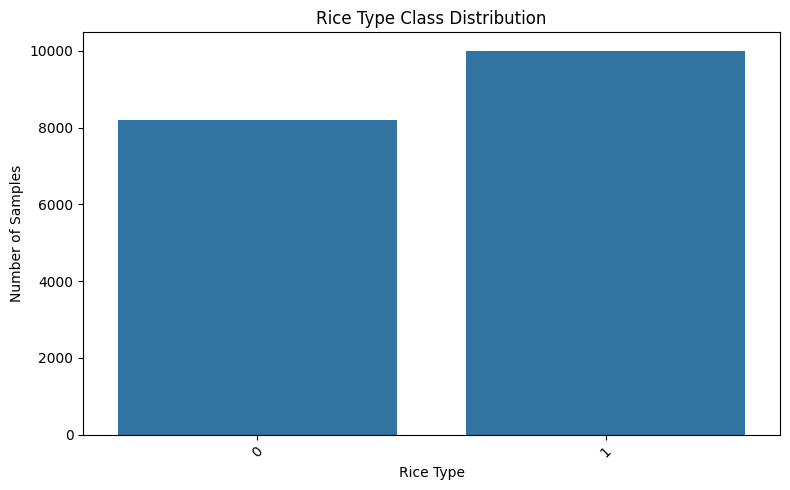

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data_df,
    x="Class"
)

plt.title("Rice Type Class Distribution")
plt.xlabel("Rice Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 10. REMOVE ID COLUMN
# ============================================================

if "id" in data_df.columns:
    data_df = data_df.drop(columns=["id"])

print(data_df.head())

   Area  MajorAxisLength  MinorAxisLength  Eccentricity  ConvexArea  \
0  4537        92.229316        64.012769      0.719916        4677   
1  2872        74.691881        51.400454      0.725553        3015   
2  3048        76.293164        52.043491      0.731211        3132   
3  3073        77.033628        51.928487      0.738639        3157   
4  3693        85.124785        56.374021      0.749282        3802   

   EquivDiameter    Extent  Perimeter  Roundness  AspectRation  Class  
0      76.004525  0.657536    273.085   0.764510      1.440796      1  
1      60.471018  0.713009    208.317   0.831658      1.453137      1  
2      62.296341  0.759153    210.012   0.868434      1.465950      1  
3      62.551300  0.783529    210.657   0.870203      1.483456      1  
4      68.571668  0.769375    230.332   0.874743      1.510000      1  


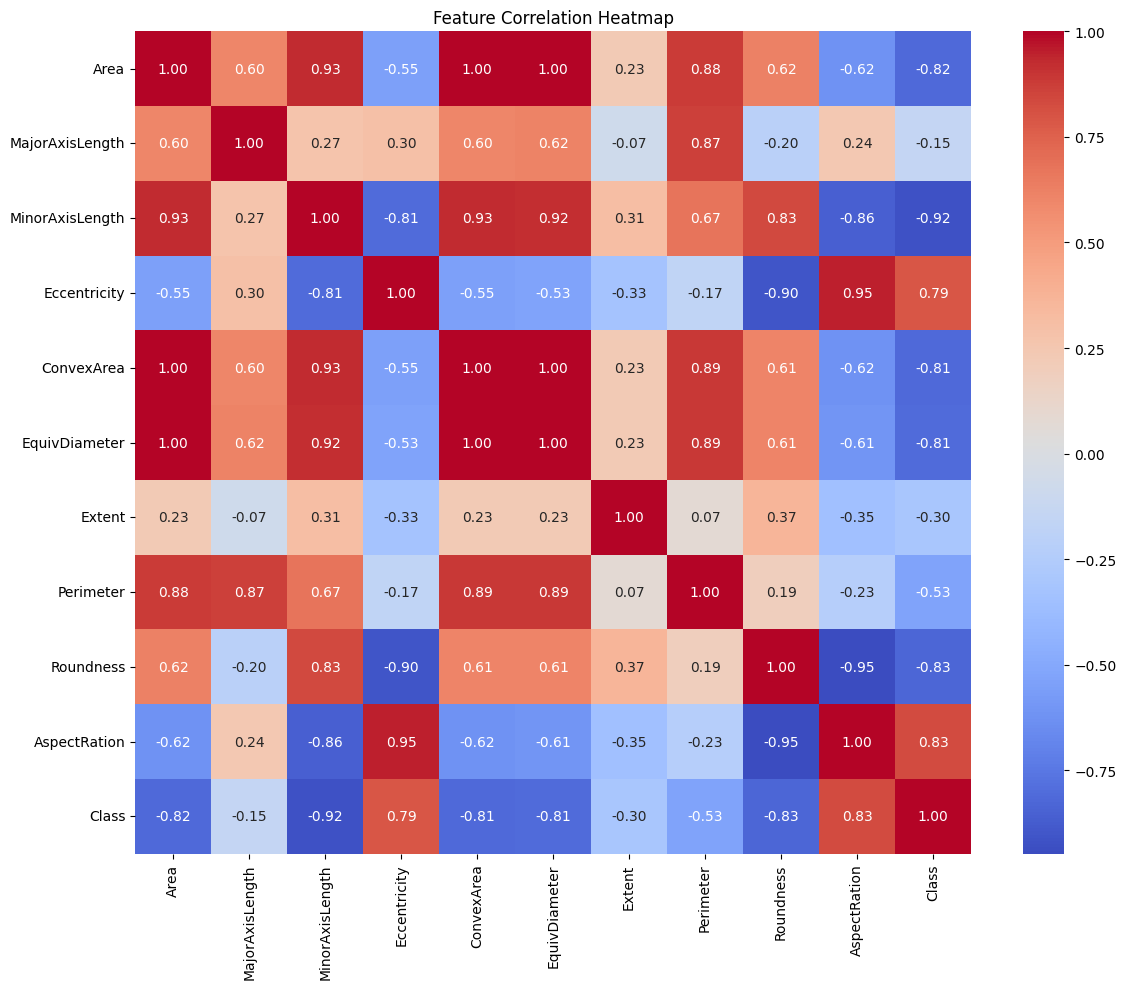

In [ ]:
# ============================================================
# 12. CORRELATION HEATMAP
# ============================================================

correlation = data_df.corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

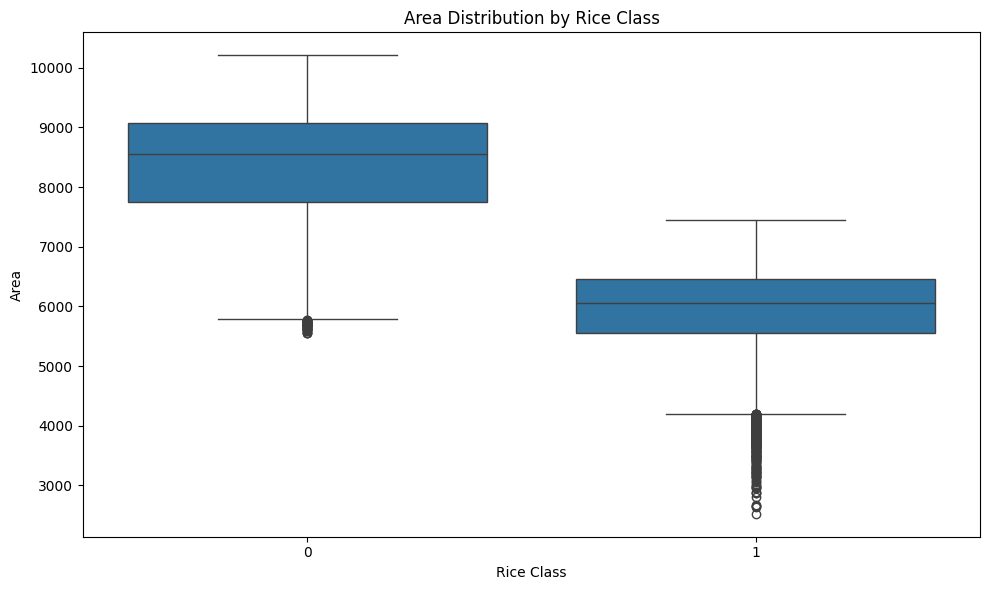

In [ ]:
# ============================================================
# 13. BOX PLOT
# ============================================================

if "Area" in data_df.columns:

    plt.figure(figsize=(10, 6))

    sns.boxplot(
        data=data_df,
        x="Class",
        y="Area"
    )

    plt.title("Area Distribution by Rice Class")
    plt.xlabel("Rice Class")
    plt.ylabel("Area")

    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# 14. CREATE FEATURES AND TARGET
# ============================================================

X = data_df.drop(columns=["Class"]).values
Y = data_df["Class"].values

print("X shape:", X.shape)
print("Y shape:", Y.shape)

print("\nFirst 5 feature rows:")
print(X[:5])

print("\nFirst 20 labels:")
print(Y[:20])

X shape: (18185, 10)
Y shape: (18185,)

First 5 feature rows:
[[4.53700000e+03 9.22293165e+01 6.40127687e+01 7.19916226e-01
  4.67700000e+03 7.60045250e+01 6.57536232e-01 2.73085000e+02
  7.64509614e-01 1.44079562e+00]
 [2.87200000e+03 7.46918807e+01 5.14004545e+01 7.25552747e-01
  3.01500000e+03 6.04710176e+01 7.13008937e-01 2.08317000e+02
  8.31658201e-01 1.45313658e+00]
 [3.04800000e+03 7.62931638e+01 5.20434911e+01 7.31210927e-01
  3.13200000e+03 6.22963412e+01 7.59153176e-01 2.10012000e+02
  8.68433574e-01 1.46595015e+00]
 [3.07300000e+03 7.70336277e+01 5.19284867e+01 7.38638694e-01
  3.15700000e+03 6.25512999e+01 7.83528812e-01 2.10657000e+02
  8.70203116e-01 1.48345605e+00]
 [3.69300000e+03 8.51247846e+01 5.63740205e+01 7.49281579e-01
  3.80200000e+03 6.85716679e+01 7.69375000e-01 2.30332000e+02
  8.74743279e-01 1.51000024e+00]]

First 20 labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [ ]:
# ============================================================
# 15. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=SEED,
    stratify=Y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (12729, 10)
Validation: (2728, 10)
Testing: (2728, 10)


In [ ]:
print("\nTraining distribution:")
print(np.bincount(y_train))

print("\nValidation distribution:")
print(np.bincount(y_val))

print("\nTesting distribution:")
print(np.bincount(y_test))


Training distribution:
[5740 6989]

Validation distribution:
[1230 1498]

Testing distribution:
[1230 1498]


In [ ]:
# ============================================================
# 16. FEATURE STANDARDIZATION
# ============================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)

X_test = scaler.transform(X_test)

print("Training data after scaling:")
print(X_train[:5])

Training data after scaling:
[[-0.53962602  0.36979472 -0.78287662  0.90916203 -0.54886243 -0.50117053
  -0.77695493 -0.16394854 -0.8193985   0.9414955 ]
 [ 0.80671889  0.67167886  0.62113886 -0.15013952  0.80167366  0.82479912
   1.7059962   0.69292121  0.56190733 -0.40584682]
 [-0.63311271 -0.42721013 -0.5317182   0.41989885 -0.64618635 -0.60055658
  -1.10143607 -0.58460724 -0.31651544  0.20427125]
 [-0.08652261 -1.25407743  0.54858964 -1.24550438 -0.12423682 -0.03421371
   1.57373818 -0.77567405  1.413223   -1.18329715]
 [-0.74434141  0.17187565 -0.94031858  0.96629431 -0.74817649 -0.72026597
  -1.59538042 -0.25617834 -1.13711488  1.04686263]]


In [ ]:
# ============================================================
# 17. PYTORCH DATASET
# ============================================================

class RiceDataset(Dataset):

    def __init__(self, X, Y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.Y = torch.tensor(
            Y,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):

        return self.X[index], self.Y[index]

In [ ]:
# ============================================================
# 18. CREATE DATASETS
# ============================================================

training_data = RiceDataset(
    X_train,
    y_train
)

validation_data = RiceDataset(
    X_val,
    y_val
)

testing_data = RiceDataset(
    X_test,
    y_test
)

print("Training samples:", len(training_data))
print("Validation samples:", len(validation_data))
print("Testing samples:", len(testing_data))

Training samples: 12729
Validation samples: 2728
Testing samples: 2728


In [ ]:
# ============================================================
# 19. DATALOADERS
# ============================================================

BATCH_SIZE = 32

train_dataloader = DataLoader(
    training_data,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_dataloader = DataLoader(
    validation_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_dataloader = DataLoader(
    testing_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [ ]:
# ============================================================
# 20. BINARY CLASSIFICATION MODEL
# ============================================================

NUM_FEATURES = X_train.shape[1]

HIDDEN_NEURONS = 32


class RiceClassifier(nn.Module):

    def __init__(self):

        super(RiceClassifier, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(
                NUM_FEATURES,
                HIDDEN_NEURONS
            ),

            nn.ReLU(),

            nn.Linear(
                HIDDEN_NEURONS,
                16
            ),

            nn.ReLU(),

            nn.Linear(
                16,
                1
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        return self.network(x)


model = RiceClassifier().to(device)

print(model)

RiceClassifier(
  (network): Sequential(
    (0): Linear(in_features=10, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


In [ ]:
summary(
    model,
    (NUM_FEATURES,)
)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                   [-1, 32]             352
              ReLU-2                   [-1, 32]               0
            Linear-3                   [-1, 16]             528
              ReLU-4                   [-1, 16]               0
            Linear-5                    [-1, 1]              17
           Sigmoid-6                    [-1, 1]               0
Total params: 897
Trainable params: 897
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


In [ ]:
# ============================================================
# 21. LOSS AND OPTIMIZER
# ============================================================

criterion = nn.BCELoss()

optimizer = Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
# ============================================================
# 22. TRAINING
# ============================================================

EPOCHS = 50

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []


for epoch in range(EPOCHS):

    # ========================================================
    # TRAINING
    # ========================================================

    model.train()

    total_train_loss = 0.0
    total_train_correct = 0

    for inputs, labels in train_dataloader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs).squeeze(1)

        # Calculate loss
        loss = criterion(
            outputs,
            labels
        )

        # Backpropagation
        loss.backward()

        optimizer.step()

        total_train_loss += loss.item()

        # Binary prediction
        predictions = (
            outputs >= 0.5
        ).float()

        total_train_correct += (
            predictions == labels
        ).sum().item()


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    total_val_loss = 0.0
    total_val_correct = 0

    with torch.no_grad():

        for inputs, labels in validation_dataloader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs).squeeze(1)

            loss = criterion(
                outputs,
                labels
            )

            total_val_loss += loss.item()

            # Binary prediction
            predictions = (
                outputs >= 0.5
            ).float()

            total_val_correct += (
                predictions == labels
            ).sum().item()


    # ========================================================
    # CALCULATE METRICS
    # ========================================================

    train_loss = (
        total_train_loss /
        len(train_dataloader)
    )

    val_loss = (
        total_val_loss /
        len(validation_dataloader)
    )

    train_accuracy = (
        total_train_correct /
        len(training_data)
    )

    val_accuracy = (
        total_val_correct /
        len(validation_data)
    )


    # ========================================================
    # STORE METRICS
    # ========================================================

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)


    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

Epoch 01/50 | Train Loss: 0.1801 | Train Acc: 0.9488 | Val Loss: 0.0374 | Val Acc: 0.9901
Epoch 02/50 | Train Loss: 0.0379 | Train Acc: 0.9880 | Val Loss: 0.0345 | Val Acc: 0.9897
Epoch 03/50 | Train Loss: 0.0362 | Train Acc: 0.9874 | Val Loss: 0.0340 | Val Acc: 0.9890
Epoch 04/50 | Train Loss: 0.0352 | Train Acc: 0.9885 | Val Loss: 0.0344 | Val Acc: 0.9886
Epoch 05/50 | Train Loss: 0.0341 | Train Acc: 0.9890 | Val Loss: 0.0338 | Val Acc: 0.9901
Epoch 06/50 | Train Loss: 0.0337 | Train Acc: 0.9887 | Val Loss: 0.0334 | Val Acc: 0.9905
Epoch 07/50 | Train Loss: 0.0329 | Train Acc: 0.9887 | Val Loss: 0.0334 | Val Acc: 0.9897
Epoch 08/50 | Train Loss: 0.0329 | Train Acc: 0.9891 | Val Loss: 0.0333 | Val Acc: 0.9897
Epoch 09/50 | Train Loss: 0.0323 | Train Acc: 0.9894 | Val Loss: 0.0331 | Val Acc: 0.9901
Epoch 10/50 | Train Loss: 0.0318 | Train Acc: 0.9885 | Val Loss: 0.0342 | Val Acc: 0.9894
Epoch 11/50 | Train Loss: 0.0317 | Train Acc: 0.9890 | Val Loss: 0.0337 | Val Acc: 0.9894
Epoch 12/5

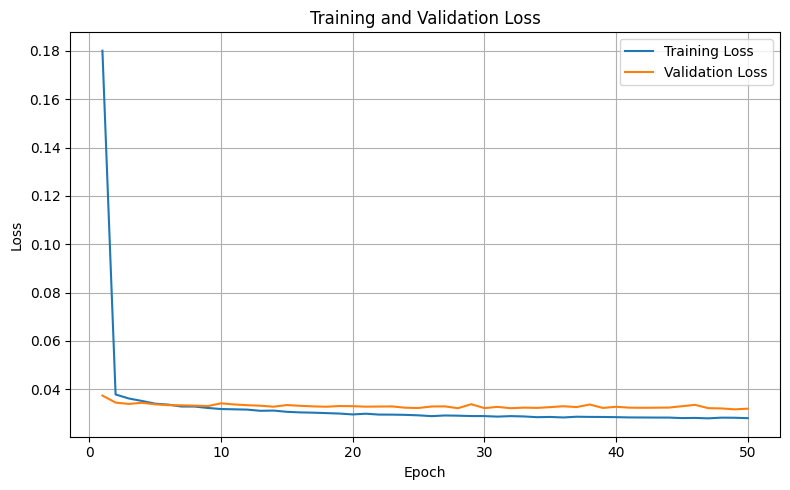

In [ ]:
# ============================================================
# 23. LOSS CURVES
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training and Validation Loss"
)

plt.legend()

plt.grid()

plt.tight_layout()

plt.show()

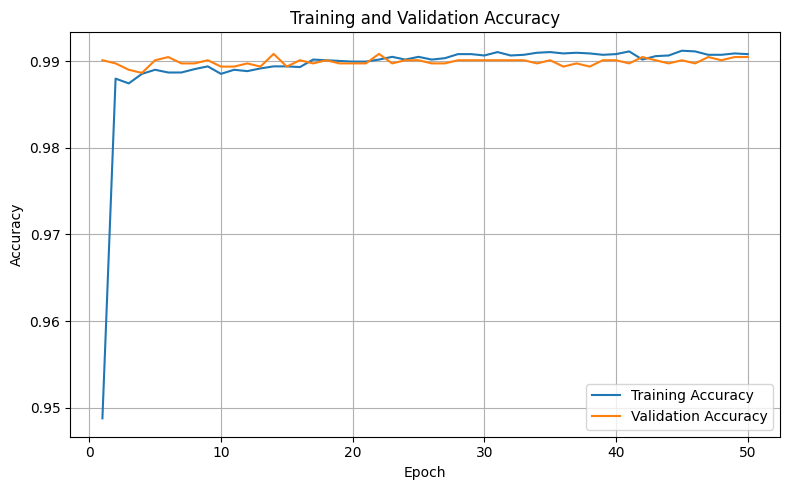

In [ ]:
# ============================================================
# 24. ACCURACY CURVES
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Training and Validation Accuracy"
)

plt.legend()

plt.grid()

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# 25. TEST EVALUATION
# ============================================================

model.eval()

total_test_loss = 0.0
total_test_correct = 0

Y_test = []
Y_pred = []

with torch.no_grad():

    for inputs, labels in test_dataloader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        # Model output
        outputs = model(inputs).squeeze(1)

        # Test loss
        loss = criterion(
            outputs,
            labels
        )

        total_test_loss += loss.item()

        # Convert probability to class
        predictions = (
            outputs >= 0.5
        ).float()

        # Count correct predictions
        total_test_correct += (
            predictions == labels
        ).sum().item()

        # Store actual labels
        Y_test.extend(
            labels.cpu().numpy().astype(int)
        )

        # Store predictions
        Y_pred.extend(
            predictions.cpu().numpy().astype(int)
        )


test_loss = (
    total_test_loss /
    len(test_dataloader)
)

test_accuracy = (
    total_test_correct /
    len(testing_data)
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(
    f"Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

Test Loss: 0.0282
Test Accuracy: 0.9905
Test Accuracy: 99.05%


In [ ]:
# ============================================================
# 26. CLASSIFICATION REPORT
# ============================================================

class_names = [
    "Class 0",
    "Class 1"
]

print(
    classification_report(
        Y_test,
        Y_pred,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

     Class 0     0.9910    0.9878    0.9894      1230
     Class 1     0.9900    0.9927    0.9913      1498

    accuracy                         0.9905      2728
   macro avg     0.9905    0.9902    0.9904      2728
weighted avg     0.9905    0.9905    0.9905      2728



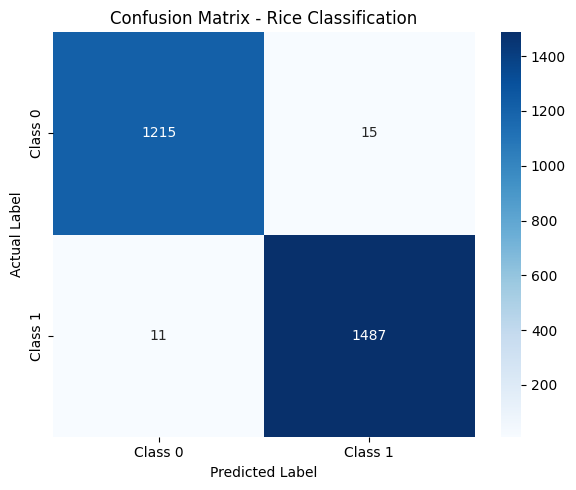

In [ ]:
# ============================================================
# 27. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    Y_test,
    Y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title(
    "Confusion Matrix - Rice Classification"
)

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================
# PREDICT A NEW RICE SAMPLE
# ==========================================

# Get the exact feature names used by the model
feature_names = data_df.drop(columns=["Class"]).columns.tolist()

print("Features used by the model:")
for i, feature in enumerate(feature_names, 1):
    print(f"{i}. {feature}")

print("\nNumber of features:", len(feature_names))


# ==========================================
# ENTER NEW RICE SAMPLE
# ==========================================

# Example values
# IMPORTANT: These values must be in the SAME ORDER
# as the feature_names printed above.

new_data = np.array([[
    15220,
    350,
    120,
    65,
    0.75,
    0.80,
    0.75,
    0.85,
    1.50,
    0.90
]])


# Check that the number of features is correct
if new_data.shape[1] != len(feature_names):
    raise ValueError(
        f"Expected {len(feature_names)} features, "
        f"but received {new_data.shape[1]}."
    )


# ==========================================
# SCALE NEW DATA
# ==========================================

# Use the SAME scaler fitted on X_train
new_data_scaled = scaler.transform(new_data)


# ==========================================
# CONVERT TO PYTORCH TENSOR
# ==========================================

new_tensor = torch.tensor(
    new_data_scaled,
    dtype=torch.float32
).to(device)


# ==========================================
# MAKE PREDICTION
# ==========================================

model.eval()

with torch.no_grad():
    probability = model(new_tensor).item()


# ==========================================
# CONVERT PROBABILITY TO CLASS
# ==========================================

prediction = 1 if probability >= 0.5 else 0


# ==========================================
# CALCULATE CONFIDENCE
# ==========================================

if prediction == 1:
    confidence = probability
else:
    confidence = 1 - probability


# ==========================================
# DISPLAY RESULT
# ==========================================

print("\n" + "=" * 40)
print("RICE CLASSIFICATION RESULT")
print("=" * 40)

print(f"Predicted Class : {prediction}")
print(f"Probability     : {probability:.4f}")
print(f"Confidence      : {confidence * 100:.2f}%")

print("=" * 40)

Features used by the model:
1. Area
2. MajorAxisLength
3. MinorAxisLength
4. Eccentricity
5. ConvexArea
6. EquivDiameter
7. Extent
8. Perimeter
9. Roundness
10. AspectRation

Number of features: 10

RICE CLASSIFICATION RESULT
Predicted Class : 0
Probability     : 0.0000
Confidence      : 100.00%
